# 01 · Exploring the dataset

Design variables (features) and functional attributes (targets) of 31 midsize sedans sold
in the USA in 2002, compiled from the published table in de Weck (2006); see the README for
the data notes. Set the `DATA_PATH` environment variable to use another CSV with the same columns.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from smalldata import FEATURES, TARGETS, load_dataset

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Set the DATA_PATH environment variable to run on another CSV with the same columns
DATA_PATH = Path(os.environ.get("DATA_PATH", ROOT / "data" / "midsize_sedans.csv"))
ds = load_dataset(DATA_PATH)
print(f"{ds.n_samples} vehicles, {len(FEATURES)} design variables, {len(TARGETS)} functional attributes")

31 vehicles, 9 design variables, 5 functional attributes


## Summary statistics and missing values

Ground clearance is missing for 5 vehicles (mean-imputed inside the model pipeline).
Towing capacity is missing for 11 vehicles: in the thesis spreadsheet these held the
placeholder 1,225 lb, which is exactly the mean of the other 20 values, so they are
treated as unknown and towing is modelled on n = 20.

In [2]:
values = pd.concat([ds.X, ds.Y], axis=1)
summary = values.describe().T
summary["missing"] = values.isna().sum()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,missing
fuel_tank_capacity_gal,31.0,16.96,1.40,14.10,16.30,17.00,17.75,20.00,0
engine_displacement_cc,31.0,2713.65,553.82,1781.00,2302.00,2500.00,3136.00,3790.00,0
front_track_width_in,31.0,60.51,1.21,57.50,59.50,60.60,61.60,62.10,0
wheelbase_in,31.0,107.28,2.91,98.90,105.70,107.10,109.00,113.00,0
ground_clearance_in,26.0,5.42,0.70,3.90,5.10,5.50,6.05,6.30,5
height_in,31.0,55.92,1.15,53.70,55.15,55.90,56.60,57.90,0
length_in,31.0,191.46,6.81,172.30,186.85,190.90,196.05,207.70,0
tire_width_mm,31.0,209.19,9.58,195.00,205.00,205.00,215.00,225.00,0
tire_diameter_in,31.0,15.42,0.50,15.00,15.00,15.00,16.00,16.00,0
passenger_volume_cuft,31.0,98.49,5.73,86.30,96.15,100.00,102.25,107.60,0


## Platform twins

Several vehicles are badge-engineered versions of each other (the same car sold under two
brands, e.g. Ford Taurus / Mercury Sable), so their design variables are identical or nearly
so. The Mitsubishi Galant has the same wheelbase, track width, ground clearance and 2.4 l
engine as the Chrysler Sebring / Dodge Stratus in this table and is grouped with them. If
one twin is in the training fold and the other in the test fold, the test score partly
measures memorisation. The `platform_group` column records these groups, and model
selection uses `GroupKFold` so a group never spans folds. Wider platform families (e.g. all
GM W-body cars) are not grouped; their members differ in body, engine or dimensions.
The table shows every group with more than one vehicle.

In [3]:
shared = ds.groups[ds.groups.duplicated(keep=False)]
cols = ["wheelbase_in", "front_track_width_in", "engine_displacement_cc", "length_in", "height_in"]
twins = pd.concat([shared, ds.X.loc[shared.index, cols]], axis=1).sort_values(["platform_group", "length_in"])
print(f"{ds.groups.nunique()} groups for {ds.n_samples} vehicles")
twins

23 groups for 31 vehicles


,platform_group,wheelbase_in,front_track_width_in,engine_displacement_cc,length_in,height_in
vehicle_id,,,,,,
Buick Century,buick_century_regal,109.0,62.0,3130,194.6,56.6
Buick Regal,buick_century_regal,109.0,62.0,3790,196.2,56.6
Chevrolet Monte Carlo,chevrolet_impala_monte_carlo,110.5,62.0,3350,197.9,55.2
Chevrolet Impala,chevrolet_impala_monte_carlo,110.5,62.0,3350,200.0,57.3
Dodge Intrepid,dodge_intrepid_chrysler_concorde,113.0,61.9,2736,203.7,55.9
Chrysler Concorde,dodge_intrepid_chrysler_concorde,113.0,61.9,2736,207.7,55.9
Ford Taurus,ford_taurus_mercury_sable,108.5,61.6,2982,197.6,56.1
Mercury Sable,ford_taurus_mercury_sable,108.5,61.6,2982,199.8,55.5
Kia Optima,hyundai_sonata_kia_optima,106.3,60.6,2351,186.2,55.5


## Correlation between design variables and functional attributes

Pearson correlation on pairwise-complete rows. With 31 samples, |r| below roughly 0.35
is not distinguishable from zero at the 5 % level (about 0.44 for towing, n = 20), so read
the weak cells with care. Twins also make the effective sample size smaller than the row count.

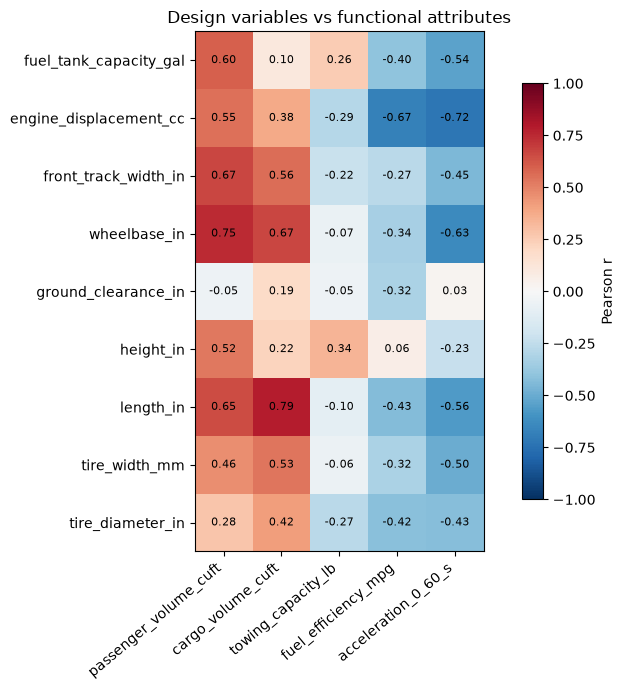

In [4]:
corr = values.corr().loc[FEATURES, TARGETS]

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(TARGETS)), TARGETS, rotation=40, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(TARGETS)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Design variables vs functional attributes")
fig.tight_layout()

## Single-variable baselines

A simple reference in the spirit of de Weck (2006): for each target, an ordinary
least-squares fit on the single most correlated design variable. These are in-sample
fits, so they are an upper bound for such a simple model, not a validated score.
`e_RMSE` is the RMSE as a percentage of the target mean.

,n,best single variable,r,R2,e_RMSE_%
target,,,,,
passenger_volume_cuft,31,wheelbase_in,0.745,0.555,3.817
cargo_volume_cuft,31,length_in,0.789,0.622,6.265
towing_capacity_lb,20,height_in,0.338,0.114,27.770
fuel_efficiency_mpg,31,engine_displacement_cc,-0.674,0.455,6.322
acceleration_0_60_s,31,engine_displacement_cc,-0.721,0.520,9.391


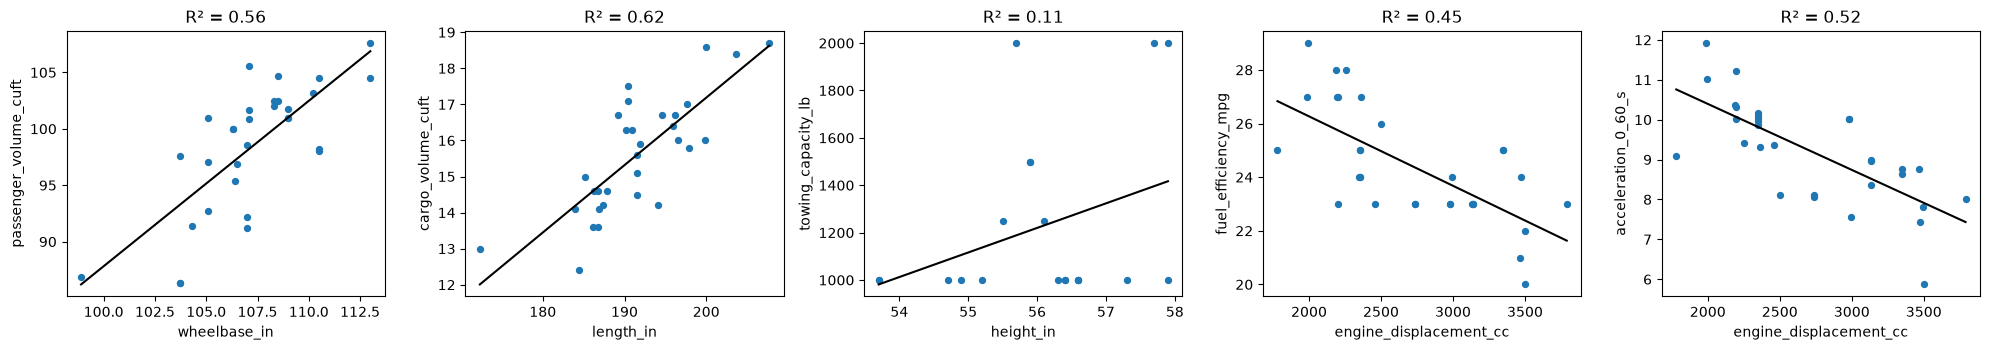

In [5]:
from sklearn.linear_model import LinearRegression

X_filled = ds.X.fillna(ds.X.mean())
fig, axes = plt.subplots(1, len(TARGETS), figsize=(4 * len(TARGETS), 3.6))
rows = []
for ax, target in zip(axes, TARGETS):
    best = corr[target].abs().idxmax()
    mask = ds.Y[target].notna()
    x, y = X_filled.loc[mask, [best]], ds.Y.loc[mask, target]
    fit = LinearRegression().fit(x, y)
    pred = fit.predict(x)
    r = np.corrcoef(x[best], y)[0, 1]
    e_rmse = 100 * np.sqrt(np.mean((pred - y) ** 2)) / y.mean()
    rows.append({"target": target, "n": int(mask.sum()), "best single variable": best,
                 "r": r, "R2": r**2, "e_RMSE_%": e_rmse})
    ax.scatter(x[best], y, s=18)
    order = np.argsort(x[best].values)
    ax.plot(x[best].values[order], pred[order], color="black")
    ax.set_xlabel(best)
    ax.set_ylabel(target)
    ax.set_title(f"R² = {r**2:.2f}")
fig.tight_layout()
pd.DataFrame(rows).set_index("target").round(3)

## Outliers

Rows with a |z-score| above 2.5 in any column. On small datasets a single unusual
vehicle can dominate a fold, so these are worth checking before modelling.

In [6]:
z = (values - values.mean()) / values.std()
outliers = z.where(z.abs() > 2.5).stack().dropna().rename("z").to_frame()
outliers["value"] = [values.at[idx, col] for idx, col in outliers.index]
outliers.rename_axis(["vehicle", "column"]).round(2)

z   value
vehicle       column                           
VW Jetta      wheelbase_in        -2.88   98.90
              length_in           -2.81  172.30
Nissan Maxima acceleration_0_60_s -2.63    5.87